## Materi Pertemuan 5 - Kecerdasan Buatan (Kamis, 22 Oktober 2026)

# Decision Tree

definisi: merupakan salah satu algoritma supervised learning yang dapat digunakan untuk klasifikasi maupun regresi. <br>
Algoritma ini membangun model yang memetakan fitur dari dataset ke label atau target menggunakan struktur pohon.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
iris = load_iris()
x = iris.data #data input
y = iris.target #data output

#split data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

- criterion: digunakan untuk metode pemisahan pada node (kotak), menggunakan 'gini' atau 'entropy' <br>
entropy: mengukur ketidakpastian dalam set data, semakin rendah entropy, semakin tinggi nilai informasi yang didapat dari pemisahan <br>
gini: mengukur seberapa sering elemen dalam dataset salah diklasifikasikan jika dipilih secara acak <br>
- max_depth: Mengukur kedalaman maksimal dari pohon untuk mengukur overfitting

In [ ]:
model1 = DecisionTreeClassifier(criterion = 'gini', max_depth = 3, random_state = 20)
model1.fit(x_train, y_train)

y_pred = model1.predict(x_test)

akurasi1 = accuracy_score(y_test, y_pred)
print(f'Accuracy Score {akurasi1 * 100:.2f}%')
print(f'Classification Report\n',classification_report(y_test, y_pred))

Accuracy Score 96.67%
Classification Report
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



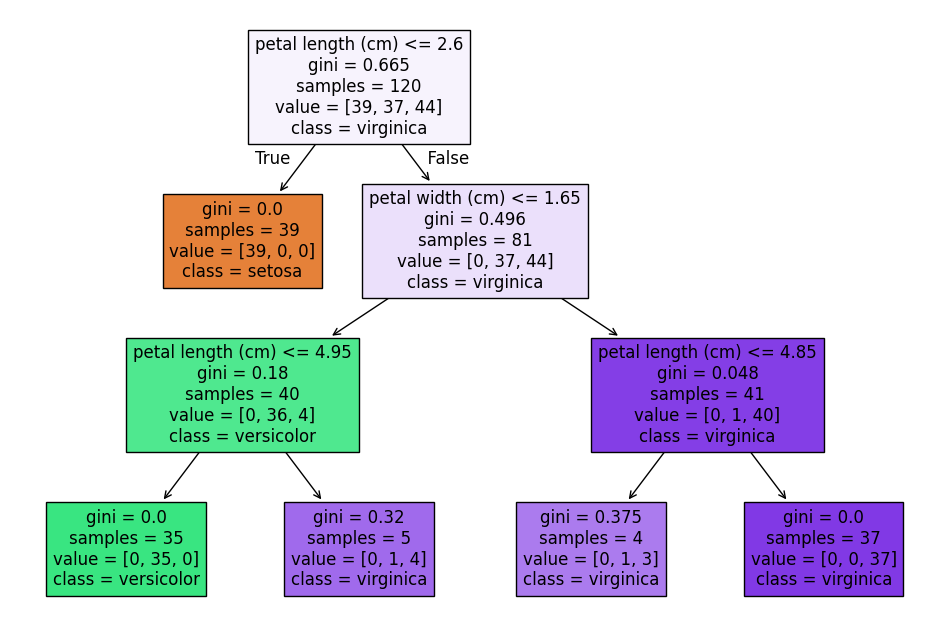

In [ ]:
# Visualisasi Decision Tree
plt.figure(figsize = (12,8))
tree.plot_tree(model1, feature_names = iris.feature_names,
               class_names = iris.target_names, filled = True)
plt.show()

# Feature Importance

Feature importance merupakan teknik yang digunakan untuk menentukan seberapa besar pengaruh setiap fitur pada prediksi model

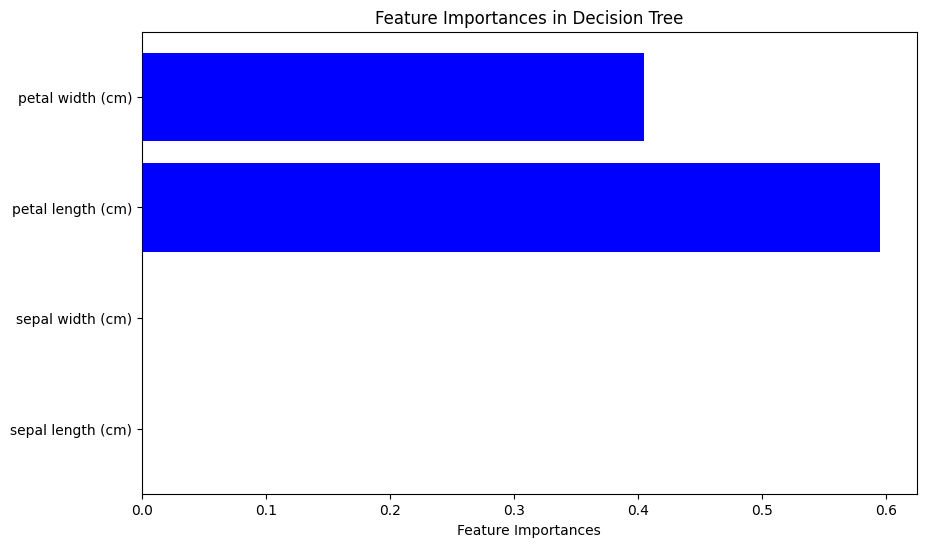

In [ ]:
#Ekstraksi feature importance
feature_importances = model1.feature_importances_

#plot
plt.figure(figsize=(10,6))
plt.barh(iris.feature_names, feature_importances, color = 'blue')
plt.xlabel('Feature Importances')
plt.title('Feature Importances in Decision Tree')
plt.show()

dari hasil tersebut, untuk training selanjutnya, data sepal width dan sepal length dihapus saja.

# Random Forest

Random Forest adalah bagian dari AI yang membangun sejumlah besar decision tree selama training dan menggabungkan hasilnya untuk membuat prediksi yang lebih akurat dan stabil

n_estimators: jumlah decision tree, semakin banyak decision tree, semakin stabil prediksinya, namun membutuhkan waktu lebih banyak komputasi

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model3 = RandomForestClassifier(n_estimators = 100, random_state =1)
model3.fit(x_train, y_train)

y_pred = model3.predict(x_test)

akurasi3 = accuracy_score(y_test, y_pred)
print(f'Accuracy Score {akurasi3 * 100:.2f}%')
print(f'Classfication Report\n', classification_report(y_test, y_pred))

Accuracy Score 96.67%
Classfication Report
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



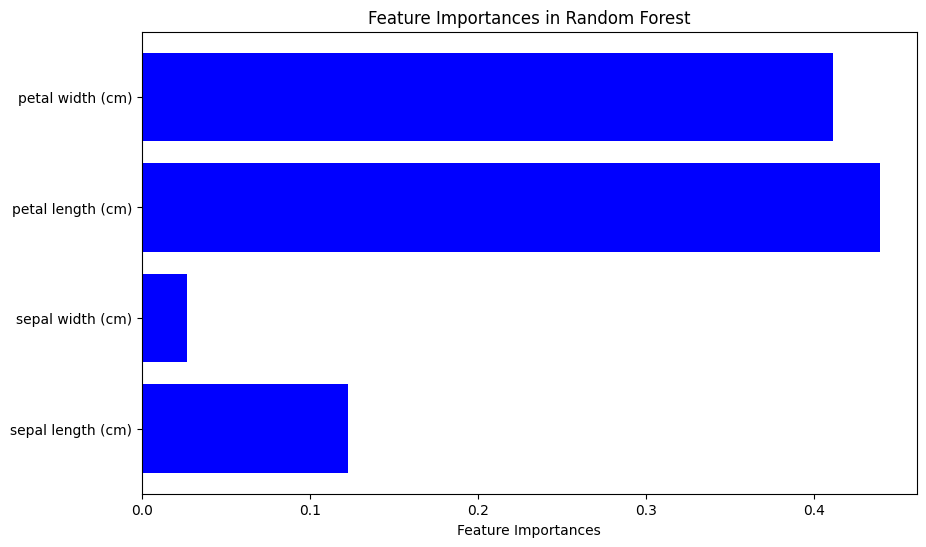

In [ ]:
#Ekstraksi feature importance
feature_importances = model3.feature_importances_

#plot
plt.figure(figsize=(10,6))
plt.barh(iris.feature_names, feature_importances, color = 'blue')
plt.xlabel('Feature Importances')
plt.title('Feature Importances in Random Forest')
plt.show()